# Reprodução auditada de Mosquito_v2.ipynb

Transferência das 61 features e de regressão logística, árvore, Random Forest e kNN, com isolamento por gravação e blocos PCM. Não é uma repetição exata dos 98,33% do notebook recebido: o corpus Windows e sua ordem original não foram fornecidos, e o particionamento aleatório de janelas não é válido para generalização por gravação.

Os modelos e limiares foram congelados antes de qualquer previsão OOF ou externa. Os resultados abaixo são reais, incluindo regressões. Não confirmam biologicamente gênero ou espécie.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np
from IPython.display import display, Image
ROOT=Path.cwd()
OUT=ROOT/'results/notebook_transfer_2026_10_14_2030'
ANALYSIS=ROOT/'results/notebook_transfer_analysis_2026_10_14_2050'
POST=ROOT/'results/notebook_transfer_postfreeze_2026_10_14_2044'
protocol=json.loads((OUT/'protocol.json').read_text())
freeze=json.loads((OUT/'freeze.json').read_text())
print('Freeze UTC:',freeze['created_utc'])
print('Origem SHA-256:',protocol['source']['sha256'])
display(pd.DataFrame(json.loads((OUT/'partition_audit.json').read_text())))

Freeze UTC: 2026-10-14T20:39:44.260795+00:00
Origem SHA-256: f0d714aa1e96443a6209ba25e73d145b22875a320e5cdf8c006394cc8e6e2d64


,fold,fit,calibration,test,group_overlap,pcm_block_overlap
0,0,300,83,230,0,0
1,1,298,137,178,0,0
2,2,282,126,205,0,0
3,final,489,124,0,0,0


## Onde o notebook original falha

A separação 70/30 usa janelas, não gravações. O StandardScaler é ajustado antes da validação cruzada interna, e a normalização de pico usa a gravação inteira. A função documentada como fase zero chama `sosfilt`, que é causal. A classificação binária significa Ae. aegypti versus outras espécies/ruído; não significa presença versus ausência de mosquito.

In [2]:
display(json.loads((OUT/'reference_split_audit.json').read_text()))
from notebook_transfer_features import extract_features
t=np.arange(16000)/16000
signal=np.sin(2*np.pi*570*t).astype(np.float32)
x,lfcc=extract_features([signal])
print('Features recebidas:',x.shape,'LFCC relativas:',lfcc.shape)

{'reference_windows': 1200,
 'source_original_dataset': 'unavailable',
 'local_subset_windows': 1200,
 'local_positive_files': 10,
 'local_negative_files': 10,
 'recording_group_overlap': 20,
 'pcm_block_overlap': 20,
 'test_windows_from_fit_recordings': 360,
 'test_windows': 360,
 'trained_on_leaky_partition': False}

Features recebidas: (1, 61) LFCC relativas: (1, 26)


## Aplicação controlada

Usamos as mesmas partições externas da v4, três dobras internas por bloco PCM e StandardScaler dentro de Pipeline. As janelas são agregadas pela média fixa das features, igual em todos os controles. Isso é uma ablação por gravação e não substitui o MIL da v4. O bloco adicional contém 26 estatísticas LFCC relativas ao piso local. A seleção e os cortes usam somente fit/CV e calibração internos; não há ajuste pelos arquivos externos.

,scope,task,variant,family,accuracy,balanced_accuracy,macro_f1_strict_union,coverage,accepted_accuracy,aegypti_correct,aegypti_n
0,dryad,binary,notebook61,lr,0.9527,0.9514,0.7711,0.9918,0.9556,19,20
1,dryad,binary,notebook61,tree,0.9560,0.8081,0.7338,1.0000,0.9560,13,20
2,dryad,binary,notebook61,rf,0.9804,0.7000,0.7807,0.9804,0.9834,8,20
3,dryad,binary,notebook61,knn,0.9853,0.8475,0.8746,0.9788,0.9883,14,20
4,dryad,binary,v4_308,lr,0.9674,0.9831,0.8248,0.9984,0.9673,20,20
5,dryad,binary,v4_lfcc334,lr,0.9674,0.9831,0.8248,0.9984,0.9673,20,20
6,dryad,species,notebook61,lr,0.5501,0.6696,0.6358,0.0000,NaN,13,20
7,dryad,species,notebook61,rf,0.5325,0.5671,0.5871,0.2724,0.7613,16,20
8,dryad,species,v4_308,lr,0.5659,0.6151,0.5817,0.0000,NaN,17,20
9,dryad,species,v4_308,rf,0.6274,0.5866,0.6067,0.4130,0.8681,18,20


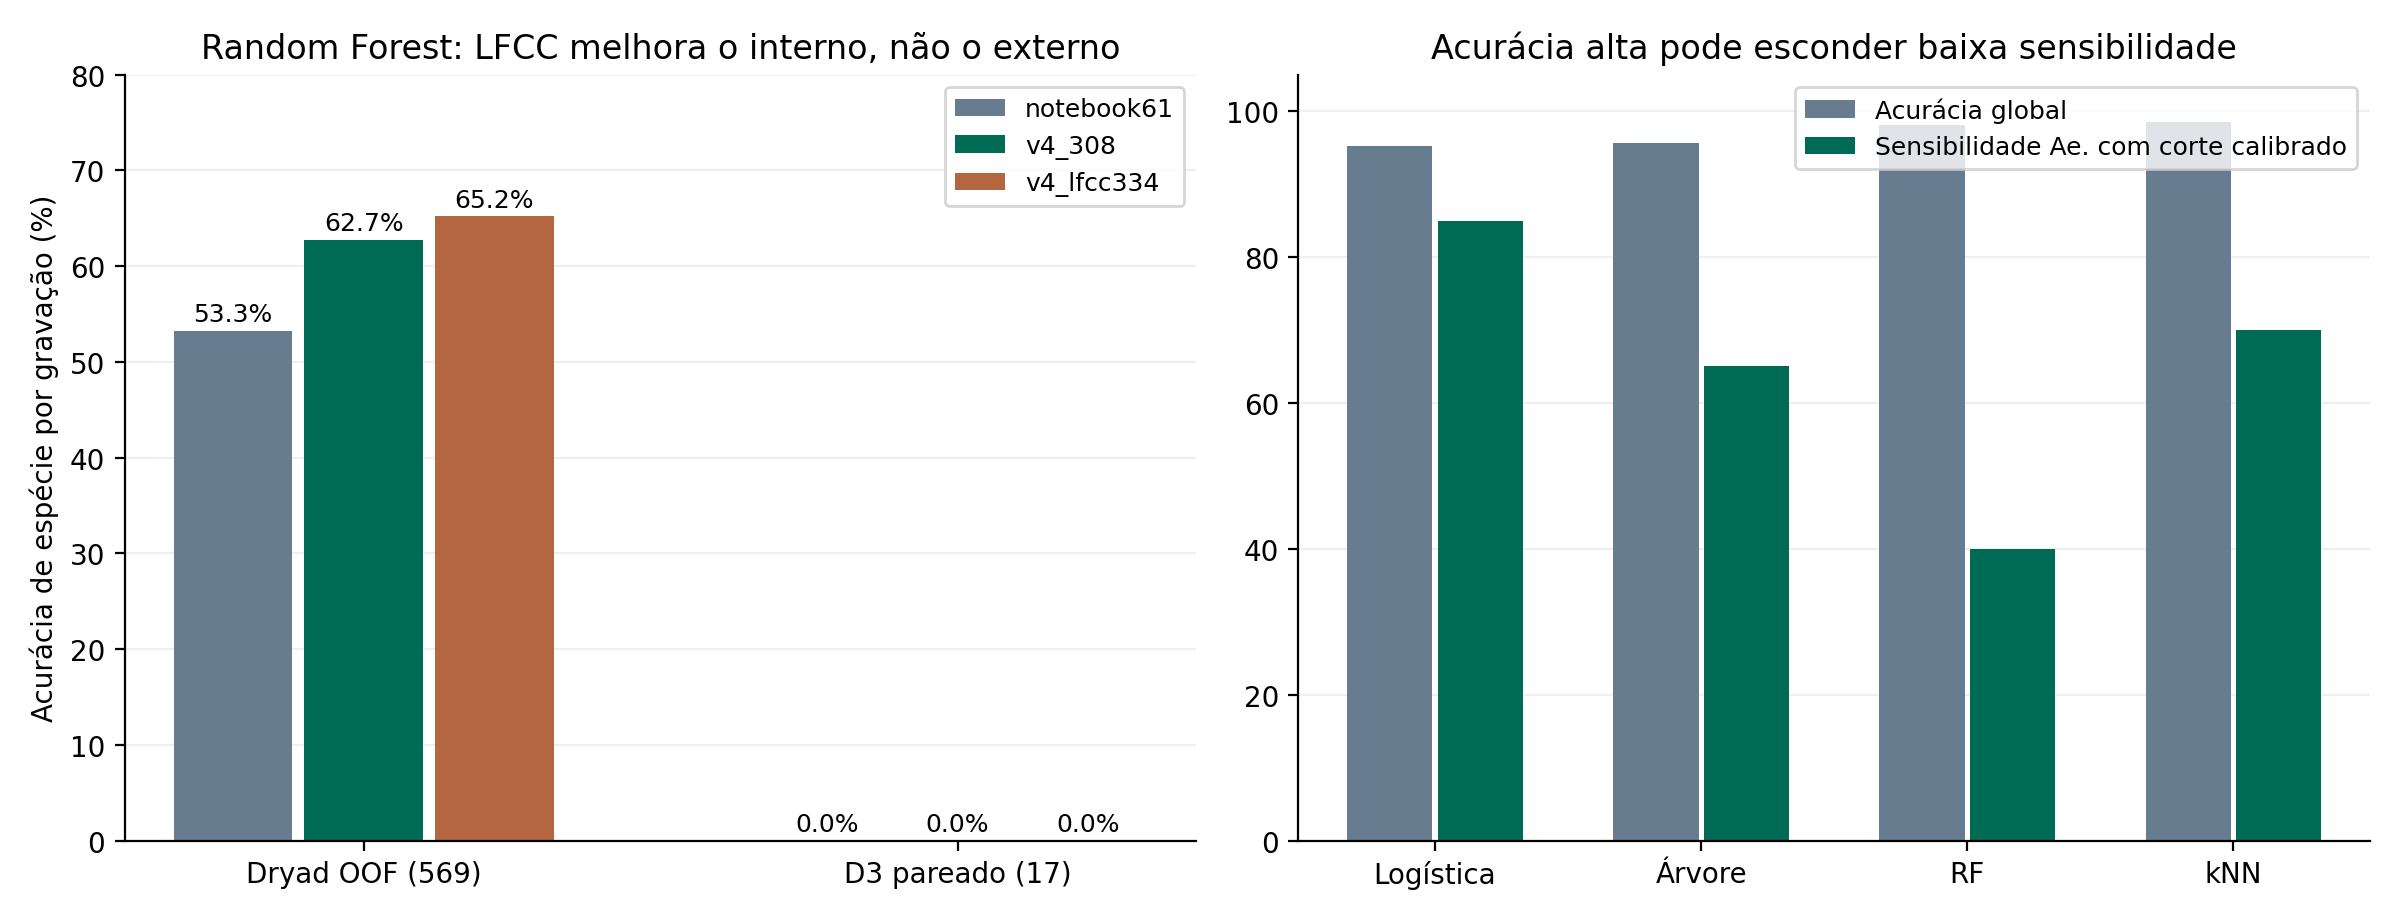

In [3]:
metrics=pd.read_csv(OUT/'metrics.csv')
cols=['scope','task','variant','family','accuracy','balanced_accuracy','macro_f1_strict_union','coverage','accepted_accuracy','aegypti_correct','aegypti_n']
display(metrics[metrics.scope.isin(['dryad','external17','drive'])][cols].round(4))
display(Image(filename=str(ANALYSIS/'comparison.png')))

## Intervalos pareados e escolha aninhada

O bootstrap reamostra gravações agrupadas por blocos PCM, estratificando conjuntos de rótulos observados. Não corrige origem biológica desconhecida nem torna o corpus conhecido uma coleta confirmatória. Os vencedores por dobra abaixo são calculados exclusivamente dos scores internos congelados, sem escolher pelo OOF.

In [4]:
display(json.loads((ANALYSIS/'paired_intervals.json').read_text()))
display(pd.read_csv(ANALYSIS/'nested_selection_metrics.csv').round(4))

{'dryad_lfcc_rf_vs_v4_rf': {'n': 569,
  'pcm_clusters': 517,
  'unit': 'recording, clustered by audited PCM block, stratified by observed source-label set',
  'repetitions': 2000,
  'metrics': {'accuracy': {'difference': 0.024604569420035083,
    'ci95': [-0.0017574692442882123, 0.05096660808435849]},
   'balanced_accuracy': {'difference': 0.0370185567039113,
    'ci95': [0.0054039890553764375, 0.0680319492386943]},
   'macro_f1_strict_union': {'difference': 0.026801856557108983,
    'ci95': [-0.003531137852922142, 0.057417534557320384]},
   'coverage': {'difference': -0.01405975395430581,
    'ci95': [-0.04217926186291743, 0.01405975395430581]},
   'accepted_accuracy': {'difference': 0.004161589652263542,
    'ci95': [-0.027107482247284827, 0.036534091872270656]}},
  'limits': 'Known recordings/corpus; biological/session independence and acquisition selection are not corrected by bootstrap.'},
 'external17_lfcc_rf_vs_v4_rf': {'n': 17,
  'pcm_clusters': 17,
  'unit': 'recording, cluste

,n,correct,accuracy,balanced_accuracy,macro_f1_support_only,macro_f1_strict_union,macro_f1_support_minus_strict,predicted_taxa_outside_support,coverage,emitted,accepted_accuracy,correct_emissions_over_all,scope,task,variant,family
0,613,600,0.9788,0.8683,0.8433,0.8433,0.0,[],0.9772,599,0.9816,0.9592,dryad,binary,nested_fit_cv_choice,per_fold
1,569,371,0.6520,0.6236,0.6335,0.6335,0.0,[],0.3989,227,0.8722,0.3480,dryad,species,nested_fit_cv_choice,per_fold


## Dois arquivos adquiridos após o freeze

S_1_D_3_89 e S_1_D_3_90 foram escolhidos por metadados, auditados por bytes e fragmentos PCM e não causaram retreinamento ou ajuste de limiar. São arquivos inéditos no acervo local de um corpus conhecido; não comprovam independência de indivíduos ou sessões. Ambos são positivos, portanto não medem especificidade ou precisão de campo.

In [5]:
selection=json.loads((POST/'selection_complete.json').read_text())
display(pd.DataFrame(selection['accepted']))
display(pd.read_csv(POST/'predictions.csv')[['group','task','variant','family','predicted_label','accepted']])
display(json.loads((OUT/'drive_cli_species.json').read_text()))

,path,group,reference_species,seconds,sha256,zip_crc32,pcm_matches,byte_duplicate
0,results/notebook_transfer_postfreeze_2026_10_1...,BioDCASE_D3|S_1_D_3_89,Aedes aegypti,30.743250,ad83e7fc1fef020789ae13c8f45cd2ded7fae145f184de...,379985661,0,False
1,results/notebook_transfer_postfreeze_2026_10_1...,BioDCASE_D3|S_1_D_3_90,Aedes aegypti,27.538875,50b8eeec64f80f894b34deb43e2e04167b7b11d975d2fa...,4250349630,0,False


,group,task,variant,family,predicted_label,accepted
0,BioDCASE_D3|S_1_D_3_89,binary,notebook61,lr,Aedes aegypti,True
1,BioDCASE_D3|S_1_D_3_89,binary,notebook61,tree,other_species_or_noise,True
2,BioDCASE_D3|S_1_D_3_89,binary,notebook61,rf,other_species_or_noise,True
3,BioDCASE_D3|S_1_D_3_89,binary,notebook61,knn,other_species_or_noise,True
4,BioDCASE_D3|S_1_D_3_89,binary,v4_308,lr,other_species_or_noise,True
5,BioDCASE_D3|S_1_D_3_89,binary,v4_lfcc334,lr,other_species_or_noise,True
6,BioDCASE_D3|S_1_D_3_89,species,notebook61,lr,Anopheles gambiae,True
7,BioDCASE_D3|S_1_D_3_89,species,notebook61,rf,Anopheles gambiae,False
8,BioDCASE_D3|S_1_D_3_89,species,v4_308,lr,Anopheles dirus,False
9,BioDCASE_D3|S_1_D_3_89,species,v4_308,rf,Anopheles gambiae,False


{'audio': 'data/raw/drive_test/drive_audio.wav',
 'task': 'species',
 'variant': 'v4_lfcc334',
 'family': 'rf',
 'candidate': 'Anopheles gambiae',
 'accepted': False,
 'emitted_label': 'ABSTAIN',
 'confidence': 0.20404483299745652,
 'probabilities': {'Aedes aegypti': 0.0853113965228763,
  'Aedes albopictus': 0.03331993534173514,
  'Aedes mediovittatus': 9.250202607511217e-35,
  'Aedes sierrensis': 0.05528689517250838,
  'Anopheles albimanus': 0.12467456087771571,
  'Anopheles arabiensis': 0.018135585092533397,
  'Anopheles atroparvus': 2.322732526418501e-05,
  'Anopheles dirus': 0.03331993534173514,
  'Anopheles farauti': 0.10374535763661549,
  'Anopheles freeborni': 0.05528689517250838,
  'Anopheles gambiae': 0.20404483299745652,
  'Anopheles merus': 0.0006490309189865897,
  'Anopheles minimus': 0.10374535763661549,
  'Anopheles quadriannulatus': 0.012690429024852855,
  'Anopheles quadrimaculatus': 2.322732526418501e-05,
  'Anopheles stephensi': 0.12467456087771571,
  'Culex pipiens':

## Como usar sem alterar a versão ativa

```bash
.venv/bin/python predict_notebook_transfer.py --audio data/raw/drive_test/drive_audio.wav --task species
.venv/bin/python predict_notebook_transfer.py --audio data/raw/drive_test/drive_audio.wav --task binary --variant notebook61 --family lr
```

Para reexecutar o treinamento, use uma pasta nova com `train(out=ROOT/'results/nome_novo')` e depois `evaluate(out=...)`. A pasta concluída não pode ser sobrescrita. O notebook original recebido deve permanecer em `external/notebook_reference_2026_10_14/Mosquito_v2.ipynb`, com o SHA registrado. Ele já está no link do Drive fornecido pelo usuário; não há áudio privado bruto neste pacote.

**Decisão:** manter experimental. O LFCC apresentou ganho interno, mas não resgatou a espécie externa. Não substituir o frontend de pesos neurais existentes sem novo treinamento/calibração. Não declarar confirmação biológica a partir de votos ou probabilidades.